In [4]:
%pip install qiskit qiskit-algorithms qiskit-aer qiskit-ibm-runtime matplotlib scipy ipywidgets pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 65.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 88.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 57.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 551.8/551.8 kB 13.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 65.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.8 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0.post0
    Uninstalling python-dateutil-2.9.0.post0:
      Successfully uninstalled python-dateutil-2.9.0.post0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [qiskit-ibm-runtime]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which 

In [ ]:
# @title

from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=getpass("Paste your IBM Quantum API key: "), # note that this is a box that you have to paste the key into
    set_as_default=True,
    overwrite=True,
)

import numpy as np
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_algorithms import TrotterQRTE
from qiskit.primitives import StatevectorEstimator


We built an interactive four-spin Ising simulation to explore the tradeoff between Trotter approximation accuracy and circuit cost. We compare first- and second-order formulas, introduce simulated CNOT noise, and test zero-noise extrapolation on neighboring-spin correlations.
---



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.linalg import expm
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_algorithms import TimeEvolutionProblem, TrotterQRTE

In [2]:
from math import sin, cos

def get_hamiltonian(L, J, h, alpha=0):
    ZZ_tuples = [
        ("ZZ", [i, i + 1], -J)
        for i in range(L - 1)
    ]

    Z_tuples = [
        ("Z", [i], -h * sin(alpha))
        for i in range(L)
    ]

    X_tuples = [
        ("X", [i], -h * cos(alpha))
        for i in range(L)
    ]

    hamiltonian = SparsePauliOp.from_sparse_list(
        [*ZZ_tuples, *Z_tuples, *X_tuples],
        num_qubits=L
    )

    return hamiltonian.simplify()

In [3]:
# Four spins, with the middle two initially set to 1.
H = get_hamiltonian(L=4, J=0.2, h=1.0, alpha=0)
initial_state = Statevector.from_label("0110")
final_time = 1.6

problem = TimeEvolutionProblem(
    H,
    initial_state=initial_state,
    time=final_time
)

print("Four-qubit experiment ready.")

Four-qubit experiment ready.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.linalg import expm
from qiskit import transpile

## Experiment: accuracy versus circuit cost

We simulate four interacting spins starting in |0110⟩.

We compare first-order and second-order Trotter formulas against
exact evolution, measuring spin correlations and final-state infidelity.

At four steps:
- First order: infidelity 0.0009997409, 28 CNOTs.
- Second order: infidelity 0.0001134937, 52 CNOTs.

Second order improves full-state accuracy, while the measured
neighboring-spin correlations are nearly identical.

does this advantage stay the same through simulated gate noise?

In [5]:
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter

L = H.num_qubits

correlation_op = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1.0) for i in range(L - 1)],
    num_qubits=L
) / (L - 1)

starting_state = Statevector(problem.initial_state)
time_limit = problem.time
H_matrix = H.to_matrix()


def exact_correlation(time):
    state = starting_state.evolve(expm(-1j * time * H_matrix))
    return float(state.expectation_value(correlation_op).real)


# Smooth reference curve, calculated once.
exact_times = np.linspace(0, time_limit, 101)
exact_values = [exact_correlation(t) for t in exact_times]


def compare_formulas(steps):
    dt = time_limit / steps
    times = np.linspace(0, time_limit, steps + 1)

    # Reference values at the actual Trotter-step boundaries.
    reference = np.array([exact_correlation(t) for t in times])

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(exact_times, exact_values, "k-", label="Exact reference")

    rows = []

    methods = [
        ("First order", LieTrotter(), "royalblue", "o"),
        ("Second order", SuzukiTrotter(order=2), "darkorange", "s")
    ]

    for name, formula, color, marker in methods:
        step_circuit = PauliEvolutionGate(
            H, time=dt, synthesis=formula
        ).definition

        state = starting_state
        values = [float(state.expectation_value(correlation_op).real)]
        full_circuit = problem.initial_state.copy()

        for _ in range(steps):
            state = state.evolve(step_circuit)
            values.append(
                float(state.expectation_value(correlation_op).real)
            )
            full_circuit.compose(step_circuit, inplace=True)

        # Use the same basic gates and compilation settings.
        compiled = transpile(
            full_circuit,
            basis_gates=["rx", "ry", "rz", "cx"],
            optimization_level=0
        )

        max_error = np.max(np.abs(np.array(values) - reference))

        rows.append((
            name,
            max_error,
            compiled.depth(),
            compiled.count_ops().get("cx", 0)
        ))

        ax.plot(
            times, values,
            linestyle="--", marker=marker,
            color=color, label=name
        )

    ax.set_xlabel("Simulated time")
    ax.set_ylabel("Average neighboring ZZ correlation")
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(f"Product-formula comparison: {steps} steps")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"Time per step: {dt:.3f}\n")
    print(f"{'Method':<15} {'Max corr. error':>16} {'Depth':>8} {'CNOTs':>8}")

    for name, error, depth, cnots in rows:
        print(f"{name:<15} {error:>16.6f} {depth:>8} {cnots:>8}")


widgets.interact(
    compare_formulas,
    steps=widgets.IntSlider(
        value=4,
        min=1,
        max=40,
        description="Steps:",
        continuous_update=False
    )
);

interactive(children=(IntSlider(value=4, continuous_update=False, description='Steps:', max=40, min=1), Output…

In [6]:
exact_final = starting_state.evolve(
    expm(-1j * time_limit * H_matrix)
)

for name, formula in [
    ("First order", LieTrotter()),
    ("Second order", SuzukiTrotter(order=2))
]:
    solver = TrotterQRTE(formula, num_timesteps=4)
    result_check = solver.evolve(problem)

    circuit_check = transpile(
        result_check.evolved_state,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    final_check = Statevector(circuit_check)

    fidelity = abs(
        np.vdot(exact_final.data, final_check.data)
    ) ** 2

    print(f"{name}: state infidelity = {max(0, 1-fidelity):.10f}")

First order: state infidelity = 0.0009997409
Second order: state infidelity = 0.0001134937


In [7]:
from scipy.linalg import expm

exact_operator = expm(-1j * final_time * H.to_matrix())
exact_state = initial_state.evolve(exact_operator)

for state, probability in exact_state.probabilities_dict().items():
    print(f"{state}: {probability:.4%}")

0000: 0.0017%
0001: 0.1285%
0010: 0.0004%
0011: 0.0691%
0100: 0.0004%
0101: 2.2469%
0110: 0.0634%
0111: 0.0545%
1000: 0.1285%
1001: 92.2067%
1010: 2.2469%
1011: 0.2719%
1100: 0.0691%
1101: 0.2719%
1110: 0.0545%
1111: 2.1857%


In [8]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.quantum_info import state_fidelity

# Apply simulated noise after every CNOT.
noise_strength = 0.01

noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(
    depolarizing_error(noise_strength, 2),
    ["cx"]
)

simulator = AerSimulator(
    method="density_matrix",
    noise_model=noise_model
)

exact_final = starting_state.evolve(
    expm(-1j * time_limit * H_matrix)
)

print("Four Trotter steps; lower infidelity is better.\n")

for name, formula in [
    ("First order", LieTrotter()),
    ("Second order", SuzukiTrotter(order=2))
]:
    solver = TrotterQRTE(formula, num_timesteps=4)
    evolution = solver.evolve(problem)

    circuit = transpile(
        evolution.evolved_state,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    # Calculate this circuit's state without noise.
    ideal_state = Statevector(circuit)
    ideal_error = 1 - state_fidelity(exact_final, ideal_state)

    # Calculate its state with simulated noise.
    noisy_circuit = circuit.copy()
    noisy_circuit.save_density_matrix()

    output = simulator.run(noisy_circuit, shots=1).result()
    noisy_state = output.data(0)["density_matrix"]
    noisy_error = 1 - state_fidelity(exact_final, noisy_state)

    print(name)
    print(f"  CNOTs: {circuit.count_ops().get('cx', 0)}")
    print(f"  Noise-free infidelity: {ideal_error:.8f}")
    print(f"  Noisy infidelity:      {noisy_error:.8f}")
    print()

Four Trotter steps; lower infidelity is better.

First order
  CNOTs: 28
  Noise-free infidelity: 0.00099974
  Noisy infidelity:      0.18911367

Second order
  CNOTs: 52
  Noise-free infidelity: 0.00011349
  Noisy infidelity:      0.31787304



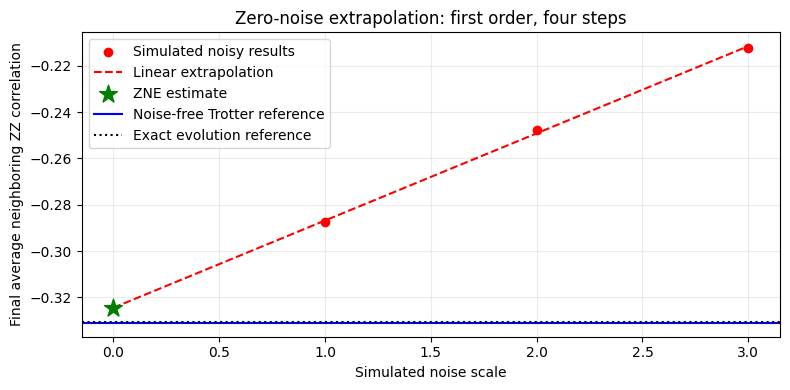

Baseline noisy correlation: -0.28750877
ZNE estimate:               -0.32446117
Noise-free Trotter:         -0.33100917
Exact evolution:           -0.33076557

Absolute error against noise-free Trotter:
Before mitigation: 0.04350040
After mitigation:  0.00654800


In [9]:
# Build one fixed circuit for the mitigation experiment.
zne_solver = TrotterQRTE(LieTrotter(), num_timesteps=4)
zne_evolution = zne_solver.evolve(problem)

zne_circuit = transpile(
    zne_evolution.evolved_state,
    basis_gates=["rx", "ry", "rz", "cx"],
    optimization_level=0
)

base_noise = 0.01


def correlation_with_noise(scale):
    # Scale the depolarizing channel.
    # Scale 0 means no noise; scale 1 is our baseline.
    strength = 1 - (1 - base_noise) ** scale

    model = NoiseModel()
    model.add_all_qubit_quantum_error(
        depolarizing_error(strength, 2),
        ["cx"]
    )

    backend = AerSimulator(
        method="density_matrix",
        noise_model=model
    )

    experiment = zne_circuit.copy()
    experiment.save_density_matrix()

    output = backend.run(experiment, shots=1).result()
    density_matrix = output.data(0)["density_matrix"]

    return float(
        density_matrix.expectation_value(correlation_op).real
    )


# These are the noisy results used for extrapolation.
noise_scales = np.array([1.0, 2.0, 3.0])
noisy_values = np.array([
    correlation_with_noise(scale) for scale in noise_scales
])

# Fit a straight line using ONLY the noisy results.
fit = np.polyfit(noise_scales, noisy_values, deg=1)
mitigated_value = float(np.polyval(fit, 0))

# References used for evaluation, not for fitting.
noise_free_value = float(
    Statevector(zne_circuit).expectation_value(correlation_op).real
)

exact_final_state = Statevector(problem.initial_state).evolve(
    expm(-1j * problem.time * problem.hamiltonian.to_matrix())
)
exact_value = float(
    exact_final_state.expectation_value(correlation_op).real
)

# Display the experiment.
plot_scales = np.linspace(0, 3, 100)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    noise_scales, noisy_values,
    color="red", label="Simulated noisy results", zorder=3
)
ax.plot(
    plot_scales, np.polyval(fit, plot_scales),
    "--", color="red", label="Linear extrapolation"
)
ax.scatter(
    [0], [mitigated_value],
    color="green", marker="*", s=180,
    label="ZNE estimate", zorder=4
)
ax.axhline(
    noise_free_value, color="blue",
    label="Noise-free Trotter reference"
)
ax.axhline(
    exact_value, color="black", linestyle=":",
    label="Exact evolution reference"
)
ax.set_xlabel("Simulated noise scale")
ax.set_ylabel("Final average neighboring ZZ correlation")
ax.set_title("Zero-noise extrapolation: first order, four steps")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Baseline noisy correlation: {noisy_values[0]:.8f}")
print(f"ZNE estimate:               {mitigated_value:.8f}")
print(f"Noise-free Trotter:         {noise_free_value:.8f}")
print(f"Exact evolution:           {exact_value:.8f}")

print("\nAbsolute error against noise-free Trotter:")
print(f"Before mitigation: {abs(noisy_values[0] - noise_free_value):.8f}")
print(f"After mitigation:  {abs(mitigated_value - noise_free_value):.8f}")

In [10]:
def interactive_mitigation(steps):
    # Keep the physical problem fixed; change only Trotter steps.
    solver = TrotterQRTE(LieTrotter(), num_timesteps=steps)
    evolution = solver.evolve(problem)

    circuit = transpile(
        evolution.evolved_state,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    ideal = Statevector(circuit)
    ideal_corr = float(
        ideal.expectation_value(correlation_op).real
    )

    exact = Statevector(problem.initial_state).evolve(
        expm(-1j * problem.time * problem.hamiltonian.to_matrix())
    )
    exact_corr = float(
        exact.expectation_value(correlation_op).real
    )

    # Run this circuit at three simulated noise strengths.
    scales = np.array([1.0, 2.0, 3.0])
    values = []

    for scale in scales:
        strength = 1 - (1 - 0.01) ** scale

        model = NoiseModel()
        model.add_all_qubit_quantum_error(
            depolarizing_error(strength, 2), ["cx"]
        )

        backend = AerSimulator(
            method="density_matrix",
            noise_model=model
        )

        experiment = circuit.copy()
        experiment.save_density_matrix()

        output = backend.run(experiment, shots=1).result()
        rho = output.data(0)["density_matrix"]
        values.append(
            float(rho.expectation_value(correlation_op).real)
        )

    fit = np.polyfit(scales, values, deg=1)
    mitigated = float(np.polyval(fit, 0))

    x = np.linspace(0, 3, 100)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(scales, values, color="red", label="Noisy results")
    ax.plot(
        x, np.polyval(fit, x),
        "r--", label="Linear extrapolation"
    )
    ax.scatter(
        [0], [mitigated], color="green",
        marker="*", s=180, label="ZNE estimate", zorder=4
    )
    ax.axhline(
        ideal_corr, color="blue",
        label="Noise-free Trotter"
    )
    ax.axhline(
        exact_corr, color="black",
        linestyle=":", label="Exact evolution"
    )
    ax.set_xlabel("Simulated noise scale")
    ax.set_ylabel("Final average neighboring ZZ correlation")
    ax.set_title(f"First-order Trotter + ZNE: {steps} steps")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    before = abs(values[0] - ideal_corr)
    after = abs(mitigated - ideal_corr)

    print(f"Steps: {steps} | Depth: {circuit.depth()}")
    print(f"CNOTs per circuit: {circuit.count_ops().get('cx', 0)}")
    print("ZNE uses three noisy circuit evaluations.\n")

    print("Absolute error against noise-free Trotter:")
    print(f"  Before mitigation: {before:.8f}")
    print(f"  After mitigation:  {after:.8f}")

    print("\nAbsolute error against exact evolution:")
    print(f"  Before mitigation: {abs(values[0] - exact_corr):.8f}")
    print(f"  After mitigation:  {abs(mitigated - exact_corr):.8f}")

    if before > 1e-12:
        reduction = 100 * (before - after) / before
        print(f"\nNoise-error reduction: {reduction:.1f}%")
        print("(A negative reduction means mitigation made it worse.)")


widgets.interact(
    interactive_mitigation,
    steps=widgets.IntSlider(
        value=4,
        min=1,
        max=20,
        description="Steps:",
        continuous_update=False
    )
);

interactive(children=(IntSlider(value=4, continuous_update=False, description='Steps:', max=20, min=1), Output…

In [11]:
from functools import lru_cache

# Freeze this dashboard's settings.
dashboard_H = problem.hamiltonian
dashboard_initial = Statevector(problem.initial_state)
dashboard_time = problem.time
dashboard_observable = correlation_op
dashboard_noise = 0.01

dashboard_matrix = dashboard_H.to_matrix()


def reference_correlation(time):
    state = dashboard_initial.evolve(
        expm(-1j * time * dashboard_matrix)
    )
    return float(
        state.expectation_value(dashboard_observable).real
    )


reference_times = np.linspace(0, dashboard_time, 101)
reference_curve = [
    reference_correlation(t) for t in reference_times
]
reference_final = reference_correlation(dashboard_time)


@lru_cache(maxsize=20)
def dashboard_experiment(steps):
    dt = dashboard_time / steps

    step_circuit = PauliEvolutionGate(
        dashboard_H,
        time=dt,
        synthesis=LieTrotter()
    ).definition

    state = dashboard_initial
    correlations = [
        float(state.expectation_value(dashboard_observable).real)
    ]

    full_circuit = problem.initial_state.copy()

    for _ in range(steps):
        state = state.evolve(step_circuit)
        correlations.append(
            float(state.expectation_value(dashboard_observable).real)
        )
        full_circuit.compose(step_circuit, inplace=True)

    circuit = transpile(
        full_circuit,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    ideal_corr = float(
        Statevector(circuit).expectation_value(
            dashboard_observable
        ).real
    )

    noisy_values = []

    for scale in [1, 2, 3]:
        strength = 1 - (1 - dashboard_noise) ** scale

        model = NoiseModel()
        model.add_all_qubit_quantum_error(
            depolarizing_error(strength, 2), ["cx"]
        )

        backend = AerSimulator(
            method="density_matrix",
            noise_model=model
        )

        experiment = circuit.copy()
        experiment.save_density_matrix()

        result_data = backend.run(
            experiment, shots=1
        ).result().data(0)

        rho = result_data["density_matrix"]
        noisy_values.append(
            float(rho.expectation_value(dashboard_observable).real)
        )

    fit = np.polyfit([1, 2, 3], noisy_values, deg=1)
    mitigated_corr = float(np.polyval(fit, 0))

    return {
        "correlations": correlations,
        "ideal_error": abs(ideal_corr - reference_final),
        "noisy_error": abs(noisy_values[0] - reference_final),
        "mitigated_error": abs(mitigated_corr - reference_final),
        "depth": circuit.depth(),
        "cnots": circuit.count_ops().get("cx", 0)
    }


# Calculate once so the slider can reuse the results.
print("Calculating 20 settings. Wait for the dashboard to appear…")
for step_count in range(1, 21):
    dashboard_experiment(step_count)


def show_dashboard(steps):
    selected = dashboard_experiment(steps)
    step_counts = np.arange(1, 21)
    records = [dashboard_experiment(int(n)) for n in step_counts]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Left: time evolution, without hardware noise.
    axes[0].plot(
        reference_times, reference_curve,
        color="black", label="Exact evolution"
    )
    axes[0].plot(
        np.linspace(0, dashboard_time, steps + 1),
        selected["correlations"],
        "o--", color="royalblue", label="Noise-free Trotter"
    )
    axes[0].set_xlabel("Simulated time")
    axes[0].set_ylabel("Average neighboring ZZ correlation")
    axes[0].set_ylim(-1.05, 1.05)
    axes[0].set_title(f"Spin evolution: {steps} steps")

    # Right: final observable error against exact evolution.
    for key, label, color in [
        ("ideal_error", "Without noise", "royalblue"),
        ("noisy_error", "With noise", "red"),
        ("mitigated_error", "With noise + ZNE", "green")
    ]:
        errors = [record[key] for record in records]
        axes[1].plot(
            step_counts, errors, ".-", color=color, label=label
        )
        axes[1].scatter(
            [steps], [selected[key]],
            color=color, s=70, zorder=4
        )

    axes[1].axvline(steps, color="gray", linestyle=":")
    axes[1].set_xlabel("Number of Trotter steps")
    axes[1].set_ylabel("Absolute final correlation error")
    axes[1].set_title("Accuracy versus step count")

    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()

    plt.tight_layout()
    plt.show()

    print(
        f"First order | {steps} steps | "
        f"Depth: {selected['depth']} | "
        f"CNOTs per circuit: {selected['cnots']}"
    )
    print(f"Noise-free error: {selected['ideal_error']:.8f}")
    print(f"Noisy error:      {selected['noisy_error']:.8f}")
    print(f"ZNE error:        {selected['mitigated_error']:.8f}")
    print("\nAll errors above compare with exact evolution.")
    print("ZNE uses three noisy evaluations at scales 1, 2, and 3.")
    print("Synthetic CNOT noise; no hardware runs or shot sampling.")


widgets.interact(
    show_dashboard,
    steps=widgets.IntSlider(
        value=4,
        min=1,
        max=20,
        description="Steps:",
        continuous_update=False
    )
);

Calculating 20 settings. Wait for the dashboard to appear…


interactive(children=(IntSlider(value=4, continuous_update=False, description='Steps:', max=20, min=1), Output…

Real quantum hardware validation.

In [15]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

hardware_service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=getpass("Paste your IBM API key: ").strip(),
    instance=input("Paste your instance CRN: ").strip()
)

hardware_backend = hardware_service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=4
)

print("Selected processor:", hardware_backend.name)

Paste your IBM API key: ··········
Paste your instance CRN: crn:v1:bluemix:public:quantum-computing:us-east:a/95b8051c845d45968e6896e9044e29ba:4b55894a-afa7-43e6-ada3-a933bafbee49::


qiskit_runtime_service._discover_account:WARNING:2026-11-15 04:56:20,814: Loading account with the given token. A saved account will not be used.


Selected processor: ibm_marrakesh


In [16]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

assert problem.hamiltonian.num_qubits == 4, "Expected four qubits."

# Same first-order, four-step experiment as our simulation.
hardware_evolution = TrotterQRTE(
    LieTrotter(), num_timesteps=4
).evolve(problem)

hardware_circuit = hardware_evolution.evolved_state.copy()
hardware_circuit.measure_all()

# Translate the circuit into gates supported by this processor.
pass_manager = generate_preset_pass_manager(
    backend=hardware_backend,
    optimization_level=1,
    seed_transpiler=42
)

hardware_isa = pass_manager.run(hardware_circuit)

print("Processor:", hardware_backend.name)
print("Compiled depth:", hardware_isa.depth())
print("Two-qubit gates:", hardware_isa.num_nonlocal_gates())
print("Planned shots: 1024")
print("Prepared only — no hardware job submitted yet.")

Processor: ibm_marrakesh
Compiled depth: 130
Two-qubit gates: 34
Planned shots: 1024
Prepared only — no hardware job submitted yet.


In [17]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

In [18]:
from qiskit_ibm_runtime import SamplerV2

# Guard against accidentally submitting again in this runtime.
if "hardware_job" not in globals():
    hardware_sampler = SamplerV2(
        mode=hardware_backend,
        options={"max_execution_time": 60}
    )

    hardware_job = hardware_sampler.run(
        [hardware_isa],
        shots=1024
    )

print("Job ID:", hardware_job.job_id())
print("Status:", hardware_job.status())

Job ID: dbsjn1gk09pc73b08i30
Status: QUEUED


Job ID: dbsf35mjjaos73ak442g

In [19]:
print(hardware_job.status())

RUNNING


In [20]:
hardware_result = hardware_job.result()
hardware_counts = hardware_result[0].data.meas.get_counts()

# Each outcome is ordered q3 q2 q1 q0.
# Matching neighbors contribute +1; different neighbors contribute -1.
def correlation_from_bitstring(bits):
    bits = bits.replace(" ", "")
    pair_values = [
        1 if bits[i] == bits[i + 1] else -1
        for i in range(len(bits) - 1)
    ]
    return sum(pair_values) / len(pair_values)

total_shots = sum(hardware_counts.values())

hardware_correlation = sum(
    count * correlation_from_bitstring(bits)
    for bits, count in hardware_counts.items()
) / total_shots

print("Measured shots:", total_shots)
print(f"Hardware correlation: {hardware_correlation:.8f}")
print("Measurement counts:", hardware_counts)

Measured shots: 1024
Hardware correlation: -0.23307292
Measurement counts: {'1000': 48, '1001': 743, '0001': 45, '1111': 43, '1010': 28, '1101': 53, '1011': 15, '0101': 21, '1110': 7, '0111': 7, '0011': 4, '1100': 6, '0110': 1, '0010': 3}


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


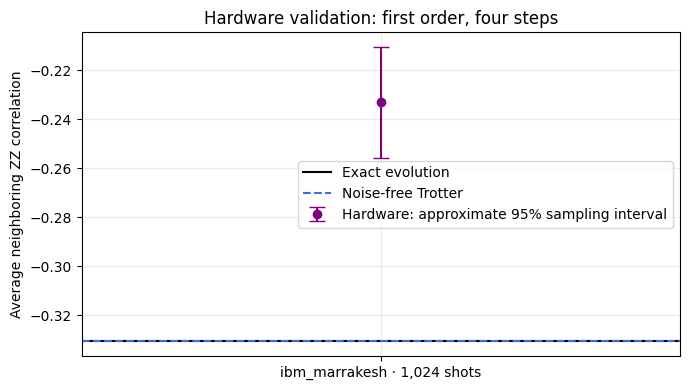

Hardware correlation: -0.23307
Sampling standard error: 0.01156
The interval describes shot uncertainty, not hardware bias.


In [21]:
# Calculate uncertainty using each shot's average pair correlation.
N = total_shots

squared_sum = sum(
    count * correlation_from_bitstring(bits) ** 2
    for bits, count in hardware_counts.items()
)

sample_variance = max(
    0.0,
    (squared_sum - N * hardware_correlation**2) / (N - 1)
)
standard_error = np.sqrt(sample_variance / N)

# Recalculate the references for this hardware experiment.
reference_state = Statevector(problem.initial_state).evolve(
    expm(-1j * problem.time * problem.hamiltonian.to_matrix())
)
exact_corr = float(
    reference_state.expectation_value(correlation_op).real
)
trotter_corr = float(
    Statevector(hardware_circuit.remove_final_measurements(inplace=False))
    .expectation_value(correlation_op).real
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(exact_corr, color="black", label="Exact evolution")
ax.axhline(
    trotter_corr, color="royalblue", linestyle="--",
    label="Noise-free Trotter"
)
ax.errorbar(
    [0], [hardware_correlation],
    yerr=[1.96 * standard_error],
    fmt="o", color="purple", capsize=6,
    label="Hardware: approximate 95% sampling interval"
)
ax.set_xticks([0])
ax.set_xticklabels([f"{hardware_job.backend().name} · {total_shots:,} shots"])
ax.set_ylabel("Average neighboring ZZ correlation")
ax.set_title("Hardware validation: first order, four steps")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Hardware correlation: {hardware_correlation:.5f}")
print(f"Sampling standard error: {standard_error:.5f}")
print("The interval describes shot uncertainty, not hardware bias.")

## Hardware experiment: accuracy versus Trotter steps

Does increasing the number of Trotter steps improve accuracy on real hardware,
or does the larger circuit introduce more noise?

We compare first order evolution with 2, 4, and 8 steps using the same
Hamiltonian, initial state, final time, processor, and compilation settings.

Each circuit uses 1,024 shots. We submit all three circuits in one job and
compare the measured neighboring-spin correlations with exact evolution
and noise-free Trotter predictions.

In [22]:
import json
import hashlib
from pathlib import Path

import pandas as pd
from IPython.display import display, clear_output

# Keep the physical problem fixed and vary only the step count.
hardware_steps = [2, 4, 8]
sweep_shots = 1024

sweep_folder = Path("hardware_step_comparison")
sweep_folder.mkdir(exist_ok=True)
sweep_record_path = sweep_folder / "hardware_sweep_job.json"

assert problem.hamiltonian.num_qubits == 4, "Expected four qubits."

# Identify the model so a saved job cannot be confused with another setup.
signature_data = (
    problem.hamiltonian.to_matrix().tobytes()
    + Statevector(problem.initial_state).data.tobytes()
    + repr((float(problem.time), hardware_steps, sweep_shots)).encode()
)
sweep_signature = hashlib.sha256(signature_data).hexdigest()

# Restore the original processor when a saved sweep is present.
if sweep_record_path.exists():
    saved_sweep = json.loads(sweep_record_path.read_text())

    if saved_sweep["signature"] != sweep_signature:
        raise ValueError(
            "The saved job uses different settings. "
            "Restore its original model before continuing."
        )

    hardware_backend = hardware_service.backend(
        saved_sweep["backend"]
    )


# Find a connected chain and use it for all three circuits.
def find_physical_chain(backend):
    if backend.coupling_map is None:
        return [0, 1, 2, 3]

    neighbors = {}

    for a, b in backend.coupling_map.get_edges():
        neighbors.setdefault(a, set()).add(b)
        neighbors.setdefault(b, set()).add(a)

    def extend(path):
        if len(path) == 4:
            return path

        for neighbor in sorted(neighbors.get(path[-1], [])):
            if neighbor not in path:
                found = extend(path + [neighbor])

                if found is not None:
                    return found

        return None

    for start in sorted(neighbors):
        found = extend([start])

        if found is not None:
            return found

    raise RuntimeError("No connected four-qubit chain found.")


sweep_layout = find_physical_chain(hardware_backend)

# Exact reference for the same initial state and evolution time.
sweep_exact_state = Statevector(problem.initial_state).evolve(
    expm(-1j * problem.time * problem.hamiltonian.to_matrix())
)

sweep_exact_corr = float(
    sweep_exact_state.expectation_value(correlation_op).real
)

sweep_circuits = []
sweep_references = []

for steps in hardware_steps:
    evolution = TrotterQRTE(
        LieTrotter(),
        num_timesteps=steps
    ).evolve(problem)

    circuit = evolution.evolved_state.copy()

    # Noise-free prediction before adding measurements.
    ideal_circuit = transpile(
        circuit,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    ideal_corr = float(
        Statevector(ideal_circuit)
        .expectation_value(correlation_op).real
    )

    sweep_references.append({
        "steps": steps,
        "exact_correlation": sweep_exact_corr,
        "ideal_trotter_correlation": ideal_corr,
        "ideal_error_vs_exact": abs(ideal_corr - sweep_exact_corr)
    })

    circuit.measure_all()
    sweep_circuits.append(circuit)

# Compile all three using identical settings.
sweep_pass_manager = generate_preset_pass_manager(
    backend=hardware_backend,
    optimization_level=1,
    initial_layout=sweep_layout,
    seed_transpiler=42
)

sweep_isa = sweep_pass_manager.run(sweep_circuits)


def measurement_mapping(circuit):
    return sorted(
        (
            circuit.find_bit(item.clbits[0]).index,
            circuit.find_bit(item.qubits[0]).index
        )
        for item in circuit.data
        if item.operation.name == "measure"
    )


sweep_mappings = [
    measurement_mapping(circuit)
    for circuit in sweep_isa
]

if not all(mapping == sweep_mappings[0] for mapping in sweep_mappings):
    raise RuntimeError(
        "Final physical measurement mappings differ. "
        "Do not submit this comparison yet."
    )

for row, circuit in zip(sweep_references, sweep_isa):
    row["compiled_depth"] = int(circuit.depth())
    row["compiled_two_qubit_gates"] = int(
        circuit.num_nonlocal_gates()
    )

sweep_plan = {
    "signature": sweep_signature,
    "backend": hardware_backend.name,
    "physical_layout": sweep_layout,
    "measurement_mapping": sweep_mappings[0],
    "shots_per_circuit": sweep_shots,
    "circuits": sweep_references
}

print("Processor:", hardware_backend.name)
print("Starting physical qubits:", sweep_layout)
print("Shots per circuit:", sweep_shots)
print("Total requested shots:", len(hardware_steps) * sweep_shots)
print("Prepared only — no hardware job submitted.")

display(pd.DataFrame(sweep_references))

Processor: ibm_marrakesh
Starting physical qubits: [0, 1, 2, 3]
Shots per circuit: 1024
Total requested shots: 3072
Prepared only — no hardware job submitted.


,steps,exact_correlation,ideal_trotter_correlation,ideal_error_vs_exact,compiled_depth,compiled_two_qubit_gates
0,2,-0.330766,-0.331369,0.000603,90,22
1,4,-0.330766,-0.331009,0.000244,130,34
2,8,-0.330766,-0.330830,0.000064,210,58


In [26]:
from qiskit_ibm_runtime import SamplerV2

submit_button = widgets.Button(
    description="Submit hardware comparison",
    button_style="warning",
    layout=widgets.Layout(width="260px")
)

submit_output = widgets.Output()


def submit_comparison(_):
    global sweep_job, sweep_submission_attempted

    with submit_output:
        clear_output(wait=True)

        # A saved record prevents another submission.
        if sweep_record_path.exists():
            record = json.loads(sweep_record_path.read_text())
            print("A comparison is already recorded.")
            print("Job ID:", record["job_id"])
            print("Use the next cell to retrieve results.")
            return

        if globals().get("sweep_submission_attempted", False):
            print("A submission was already attempted.")
            print("Check IBM's job dashboard before trying again.")
            return

        sweep_submission_attempted = True
        submit_button.disabled = True

        try:
            sampler = SamplerV2(mode=hardware_backend)

            sweep_job = sampler.run(
                sweep_isa,
                shots=sweep_shots
            )

            print("Job ID:", sweep_job.job_id())

            record = dict(sweep_plan)
            record["job_id"] = sweep_job.job_id()

            sweep_record_path.write_text(
                json.dumps(record, indent=2)
            )

            print("Processor:", record["backend"])
            print("Submitted 2-, 4-, and 8-step circuits.")
            print("Status:", sweep_job.status())
            print("Job record saved:", sweep_record_path)
            print("Run the next cell to check for results.")

        except Exception as error:
            print(type(error).__name__ + ":", str(error))
            print(
                "Check IBM's job dashboard before retrying. "
                "The submission may have reached IBM."
            )


submit_button.on_click(submit_comparison)

submit_button.disabled = (
    sweep_record_path.exists()
    or globals().get("sweep_submission_attempted", False)
)

display(submit_button, submit_output)

if sweep_record_path.exists():
    record = json.loads(sweep_record_path.read_text())
    print("Existing comparison job:", record["job_id"])

Button(button_style='warning', description='Submit hardware comparison', disabled=True, layout=Layout(width='2…

Output()

Existing comparison job: dbsjpuhabdes73fr86eg


Job ID: dbsjpuhabdes73fr86eg
Status: DONE


,steps,shots,exact_correlation,ideal_trotter_correlation,hardware_correlation,sampling_standard_error,ideal_error_vs_exact,hardware_error_vs_exact,hardware_gap_vs_ideal,compiled_depth,compiled_two_qubit_gates
0,2,1024,-0.330766,-0.331369,-0.246094,0.010986,0.000603,0.084672,0.085275,90,22
1,4,1024,-0.330766,-0.331009,-0.152344,0.013036,0.000244,0.178422,0.178665,130,34
2,8,1024,-0.330766,-0.330830,0.013672,0.015600,0.000064,0.344437,0.344501,210,58


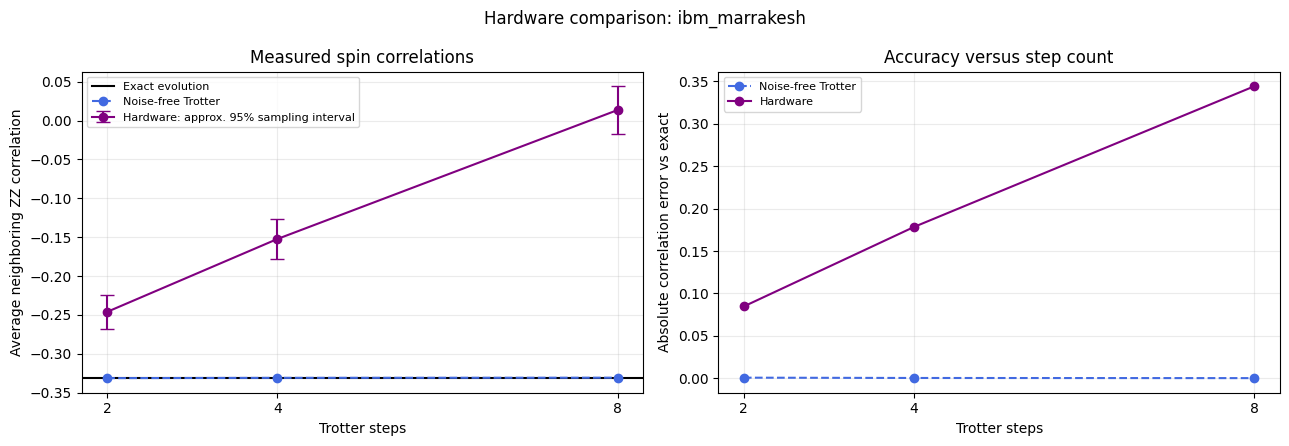

Smallest observed hardware correlation error: 2 steps.
Absolute error: 0.08467182
Compiled two-qubit gates: 22

This compares three settings in one hardware batch.
Small differences may reflect sampling variation.
Sampling intervals exclude device bias and drift.
ZNE was demonstrated separately in simulation.
Saved results and graph in: hardware_step_comparison


In [27]:
# Treat each complete shot as one observation.
# The three neighboring pairs within a shot are not independent.
def summarize_counts(counts):
    shots = int(sum(counts.values()))

    if shots < 2:
        raise ValueError("At least two shots are required.")

    weighted_sum = 0.0
    squared_sum = 0.0

    for bits, count in counts.items():
        bits = bits.replace(" ", "")

        if len(bits) != 4:
            raise ValueError("Expected four measured bits.")

        value = sum(
            1 if bits[i] == bits[i + 1] else -1
            for i in range(3)
        ) / 3

        weighted_sum += count * value
        squared_sum += count * value**2

    mean = weighted_sum / shots

    variance = max(
        0.0,
        (squared_sum - shots * mean**2) / (shots - 1)
    )

    standard_error = np.sqrt(variance / shots)

    return float(mean), float(standard_error), shots


if not sweep_record_path.exists():
    print("No saved comparison job found.")
    print("Submit once above, or restore hardware_sweep_job.json.")

else:
    record = json.loads(sweep_record_path.read_text())

    if record["signature"] != sweep_signature:
        raise ValueError(
            "The saved job does not match the current model."
        )

    completed_job = hardware_service.job(record["job_id"])

    print("Job ID:", completed_job.job_id())
    print("Status:", completed_job.status())

    if not completed_job.done():
        if completed_job.errored():
            print("Job error:", completed_job.error_message())
        else:
            print("Not finished yet. Rerun this cell later.")
            print("Do not submit another job.")

    else:
        results = completed_job.result()

        if len(results) != len(record["circuits"]):
            raise ValueError("Unexpected number of circuit results.")

        comparison_rows = []
        counts_by_step = []

        for reference, result in zip(record["circuits"], results):
            counts = result.data.meas.get_counts()
            measured, error, shots = summarize_counts(counts)

            exact = reference["exact_correlation"]
            ideal = reference["ideal_trotter_correlation"]

            comparison_rows.append({
                "steps": reference["steps"],
                "shots": shots,
                "exact_correlation": exact,
                "ideal_trotter_correlation": ideal,
                "hardware_correlation": measured,
                "sampling_standard_error": error,
                "ideal_error_vs_exact": abs(ideal - exact),
                "hardware_error_vs_exact": abs(measured - exact),
                "hardware_gap_vs_ideal": abs(measured - ideal),
                "compiled_depth": reference["compiled_depth"],
                "compiled_two_qubit_gates": (
                    reference["compiled_two_qubit_gates"]
                )
            })

            counts_by_step.append({
                "steps": reference["steps"],
                "counts": {
                    str(bits): int(count)
                    for bits, count in counts.items()
                }
            })

        comparison = pd.DataFrame(comparison_rows)
        display(comparison)

        comparison.to_csv(
            sweep_folder / "hardware_comparison.csv",
            index=False
        )

        (sweep_folder / "hardware_results.json").write_text(
            json.dumps({
                "job_id": completed_job.job_id(),
                "backend": record["backend"],
                "experiment": record,
                "results": comparison_rows,
                "counts_by_step": counts_by_step
            }, indent=2)
        )

        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

        # Left: actual observable values and sampling uncertainty.
        axes[0].axhline(
            comparison["exact_correlation"].iloc[0],
            color="black",
            label="Exact evolution"
        )

        axes[0].plot(
            comparison["steps"],
            comparison["ideal_trotter_correlation"],
            "o--",
            color="royalblue",
            label="Noise-free Trotter"
        )

        axes[0].errorbar(
            comparison["steps"],
            comparison["hardware_correlation"],
            yerr=1.96 * comparison["sampling_standard_error"],
            fmt="o-",
            color="purple",
            capsize=5,
            label="Hardware: approx. 95% sampling interval"
        )

        axes[0].set_title("Measured spin correlations")
        axes[0].set_ylabel("Average neighboring ZZ correlation")

        # Right: distance from the exact reference.
        axes[1].plot(
            comparison["steps"],
            comparison["ideal_error_vs_exact"],
            "o--",
            color="royalblue",
            label="Noise-free Trotter"
        )

        axes[1].plot(
            comparison["steps"],
            comparison["hardware_error_vs_exact"],
            "o-",
            color="purple",
            label="Hardware"
        )

        axes[1].set_title("Accuracy versus step count")
        axes[1].set_ylabel("Absolute correlation error vs exact")

        for ax in axes:
            ax.set_xlabel("Trotter steps")
            ax.set_xticks(hardware_steps)
            ax.grid(alpha=0.25)
            ax.legend(fontsize=8)

        fig.suptitle(
            f"Hardware comparison: {record['backend']}"
        )
        fig.tight_layout()

        fig.savefig(
            sweep_folder / "hardware_comparison.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        best = comparison.loc[
            comparison["hardware_error_vs_exact"].idxmin()
        ]

        print(
            f"Smallest observed hardware correlation error: "
            f"{int(best['steps'])} steps."
        )
        print(
            f"Absolute error: "
            f"{best['hardware_error_vs_exact']:.8f}"
        )
        print(
            f"Compiled two-qubit gates: "
            f"{int(best['compiled_two_qubit_gates'])}"
        )

        print("\nThis compares three settings in one hardware batch.")
        print("Small differences may reflect sampling variation.")
        print("Sampling intervals exclude device bias and drift.")
        print("ZNE was demonstrated separately in simulation.")
        print("Saved results and graph in:", sweep_folder)

In [30]:
# Explore the completed hardware results without submitting new jobs.
def explore_hardware(steps):
    selected = comparison.loc[
        comparison["steps"] == steps
    ].iloc[0]

    values = [
        selected["exact_correlation"],
        selected["ideal_trotter_correlation"],
        selected["hardware_correlation"]
    ]

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.bar(
        ["Exact", "Noise-free Trotter", "Hardware"],
        values,
        color=["gray", "royalblue", "purple"],
        alpha=0.8
    )

    ax.errorbar(
        [2],
        [selected["hardware_correlation"]],
        yerr=[1.96 * selected["sampling_standard_error"]],
        fmt="none",
        ecolor="black",
        capsize=6
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel("Average neighboring ZZ correlation")
    ax.set_title(f"Hardware comparison: {steps} Trotter steps")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

    print(f"Measured shots: {int(selected['shots'])}")
    print(f"Compiled depth: {int(selected['compiled_depth'])}")
    print(
        "Compiled two-qubit gates:",
        int(selected["compiled_two_qubit_gates"])
    )
    print(
        f"Hardware error vs exact: "
        f"{selected['hardware_error_vs_exact']:.8f}"
    )
    print("Error bar: approximate 95% sampling interval.")
    print("Saved hardware measurements; no new job submitted.")


if "comparison" in globals():
    widgets.interact(
        explore_hardware,
        steps=widgets.SelectionSlider(
            options=[2, 4, 8],
            value=4,
            description="Steps:",
            continuous_update=False
        )
    );
else:
    print("Retrieve the completed hardware results above first.")

interactive(children=(SelectionSlider(continuous_update=False, description='Steps:', index=1, options=(2, 4, 8…

## What the hardware comparison tells us

Increasing the number of Trotter steps can improve the ideal approximation,
but it also changes the compiled circuit depth and two-qubit gate count.

We compare exact evolution, noise-free Trotter predictions, and hardware
measurements to investigate this tradeoff for our four-spin experiment.

The hardware table reports the smallest observed correlation error among
the three tested settings. This does not establish a universal optimal
step count, and small differences may be due to sampling variation.

Error bars show approximate 95% sampling intervals. They do not include
systematic device bias or calibration drift.

Our ZNE experiment uses simulated depolarizing noise. The hardware
comparison is a separate validation experiment and does not apply ZNE
or reconstruct full-state fidelity.